# 07 — The optimal interval under dephasing-only idle noise

## Premise

Everything up to 06c charged idling as Selene charges it: explicit `phased_x(0,0)` operations
at the depolarizing rate `p_1q`, with the number of operations per Δt unit (`k`) chosen by us.
That made λ a modelling choice rather than a property of any device, and it put X noise on
idle qubits, which trapped ions largely do not have.

This notebook keeps the **form** of the idle noise physical and leaves its **size** as a
parameter, then derives Δt* as a function of those parameters.

**The form, and its source.** Quantinuum's emulator noise model
([docs](https://docs.quantinuum.com/systems/user_guide/emulator_user_guide/noise_model.html))
models memory error during idling and transport as **Pauli Z only**, with two terms applied
together:

| term | emulator form | here |
| --- | --- | --- |
| linear | Z with probability `r·d` | `γ·Δt` |
| quadratic | `RZ(f·d)`, or in stabilizer simulation Z with probability `sin²(f·d/2)` | `sin²(√c·Δt) ≈ c·Δt²` |

There is no idle bit-flip or T1 term; X and Y arise only from spontaneous emission during
gates. The H2 data sheet gives the size of the effect (memory error 2×10⁻⁴ per qubit per
depth-1 circuit, typical) but not its form.

**Two consequences, both built in below.**
1. **X-basis memory.** A `|0_L⟩` memory decoded on Z-checks cannot see Z errors at all, so
   under this noise it has no idle cost and no trade-off (§2 shows it). The memory is `|+_L⟩`,
   decoded on X-checks.
2. **Idle error need not be linear in time.** The paper's Eq. 1 is linear (`p·λ·Δt`); the
   quadratic term is not. The next section derives what that changes.

**Gate and readout noise** keep H2's ratios
([H2 emulator parameters](https://docs.quantinuum.com/systems/user_guide/emulator_user_guide/emulators/h2_emulators.html),
H2-1E, 2025-07-16), scaled up uniformly so that `p_L` is measurable at d ≤ 7 (§0). §6 tests
that the scaling does not move Δt*.

## 0. Setup

**Gate and readout noise** at H2-1E's ratios, scaled by `P2 / 1.05e-3`:

| | H2-1E | here |
| --- | --- | --- |
| `p_1q` (`DEPOLARIZE1` after each 1q gate) | 1.89e-5 | 9.0e-5 |
| `p_2q` (`DEPOLARIZE2` after each CX) | 1.05e-3 | 5.0e-3 |
| `p_meas` (flip of the record) | 6e-4 (0) / 1.39e-3 (1) | 4.7e-3, symmetric (the mean) |
| `p_init` | 4e-5 | 1.9e-4 |

**Idle parameters**, relative to `p_2q`: γ/p_2q ∈ {0.15, 0.3, 0.6} (linear only),
c/p_2q ∈ {0.0025, 0.01, 0.04} (quadratic only), and one mixed point (0.3, 0.01) that is not used
for calibration.

**Design.** Rotated code, X-basis memory, `T = 192 t_R` fixed (the paper's design), Δt on a
log grid from 1 to `T/d` (so `N ≥ d`), Stim + PyMatching on the exact detector error model
(`circuit_level.stim_memory`), 2 seeds × 100,000 shots per point. The rate per unit time is
`R = −ln(1 − 2·p_L)/(2T)` (Eq. A3 inverted).

In [1]:
import sys, pathlib, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['mathtext.fontset'] = 'cm'   # LaTeX-style math in figure labels
from scipy.optimize import least_squares

sys.path.insert(0, str(pathlib.Path.cwd().parent / 'src'))
from qec_timing.circuit_level.stim_memory import StimMemory
from qec_timing.circuit_level import runcache

pd.set_option('display.width', 200)
FIGDIR = pathlib.Path('figures')
BLUE, ORANGE, AQUA, GRAY = '#1f5aa6', '#d9822b', '#2a9d8f', '#888888'
DCOL = {3: BLUE, 5: ORANGE, 7: AQUA}

# H2-1E emulator noise (2025-07-16)
H2 = dict(p1=1.89e-5, p2=1.05e-3, p_meas0=6e-4, p_meas1=1.39e-3, p_init=4e-5)
P2 = 5e-3
SCALE = P2 / H2['p2']
GATES = dict(p1=H2['p1'] * SCALE, p2=P2,
             p_meas=0.5 * (H2['p_meas0'] + H2['p_meas1']) * SCALE,
             p_init=H2['p_init'] * SCALE)

T = 192
DISTANCES = (3, 5, 7)
SHOTS, SEEDS = 100_000, (1, 2)
LIN = (0.15, 0.3, 0.6)          # gamma / p2
QUAD = (0.0025, 0.01, 0.04)     # c / p2
MIXED = (0.3, 0.01)             # (gamma, c) / p2, held out of calibration
EXP = '07_dephasing_interval'

print({k: f'{v:.3g}' for k, v in GATES.items()}, f' scale x{SCALE:.2f}')

{'p1': '9e-05', 'p2': '0.005', 'p_meas': '0.00474', 'p_init': '0.00019'}  scale x4.76


In [2]:
def dt_grid(d, n=16):
    # Delta t = T/R on a log grid from 1 to T/d; R is an integer, so Delta t is exact.
    Rs = sorted({int(round(T / x)) for x in np.geomspace(1.0, T / d, n)
                 if round(T / x) >= d}, reverse=True)
    return [(T / R, R) for R in Rs]


def run_point(d, dt, R, gamma, c, gates, basis, shots, seed):
    params = dict(code='rotated', d=d, basis=basis, dt=float(dt), rounds=int(R),
                  gamma=float(gamma), c=float(c), shots=int(shots), seed=int(seed),
                  **{k: float(v) for k, v in gates.items()})
    hit = runcache.load(EXP, params)
    if hit is None:
        # stim_memory applies Z with probability sin^2(kappa*dt/2); kappa = 2 sqrt(c)
        M = StimMemory('rotated', d, basis=basis, **gates,
                       dephase_linear=gamma, dephase_quad=2 * np.sqrt(c))
        _, _, f = M.logical_error(tau=dt, rounds=R, shots=shots, seed=seed)
        hit = dict(fails=int(f), shots=int(shots))
        runcache.save(EXP, params, hit)
    return hit['fails'], hit['shots']


def rate(F, N):
    p = F / N
    s = np.sqrt(max(p * (1 - p), 1e-12) / N)
    if p >= 0.5:
        return np.nan, np.nan
    return -np.log(1 - 2 * p) / (2 * T), s / ((1 - 2 * p) * T)


def sweep(d, gamma, c, gates=GATES, basis='X', seeds=SEEDS, shots=SHOTS):
    rows = []
    for dt, R in dt_grid(d):
        F = N = 0
        for sd in seeds:
            f, n = run_point(d, dt, R, gamma, c, gates, basis, shots, sd)
            F, N = F + f, N + n
        r, sr = rate(F, N)
        rows.append(dict(dt=dt, R=R, pL=F / N, r=r, sr=sr))
    return pd.DataFrame(rows)


def optimum(df, rel=1.3, n_boot=2000, seed=0):
    # tau*: weighted parabola in log(dt) fitted to log(rate) over the points within `rel` of the
    # lowest (at least 5). Error: parametric bootstrap of the rates, 16th-84th percentile.
    # band: grid points whose rate is within 1 sigma (combined) of the lowest.
    # saturated points (p_L near 1/2) carry no rate information and are dropped
    df = df[(df.pL < 0.45) & np.isfinite(df.r)].reset_index(drop=True)
    x, y, s = np.log(df.dt.values), df.r.values, df.sr.values
    i = int(np.argmin(y))
    w = np.where(y <= rel * y[i])[0]
    lo, hi = w.min(), w.max()
    while hi - lo + 1 < 5 and (lo > 0 or hi < len(y) - 1):
        lo, hi = max(lo - 1, 0), min(hi + 1, len(y) - 1)
    sl = slice(lo, hi + 1)

    def vertex(yy):
        a, b, _ = np.polyfit(x[sl], np.log(yy[sl]), 2, w=yy[sl] / s[sl])
        if a <= 0:
            return x[sl][np.argmin(yy[sl])]
        return float(np.clip(-b / (2 * a), x[sl][0], x[sl][-1]))

    rng = np.random.default_rng(seed)
    boots = [vertex(np.maximum(y + rng.normal(0, s), 1e-12)) for _ in range(n_boot)]
    q16, q84 = np.exp(np.percentile(boots, [16, 84]))
    band = df.dt.values[(y - y[i]) <= np.sqrt(s ** 2 + s[i] ** 2)]
    return dict(dt_star=float(np.exp(vertex(y))), lo=float(q16), hi=float(q84),
                lowest=float(df.dt.values[i]), band=(round(band.min(), 2), round(band.max(), 2)),
                interior=bool(0 < i < len(y) - 1))


def idle_of(key):
    fam, val = key[0], key[1]
    if fam == 'lin':
        return val * P2, 0.0
    if fam == 'quad':
        return 0.0, val * P2
    return val[0] * P2, val[1] * P2


for d in DISTANCES:
    print(f'd={d}: dt grid', [round(t, 2) for t, _ in dt_grid(d)])

d=3: dt grid [1.0, 1.32, 1.75, 2.29, 3.05, 4.0, 5.33, 6.86, 9.14, 12.0, 16.0, 21.33, 27.43, 38.4, 48.0, 64.0]
d=5: dt grid [1.0, 1.27, 1.63, 2.06, 2.63, 3.37, 4.27, 5.49, 7.11, 8.73, 11.29, 14.77, 19.2, 24.0, 32.0, 38.4]
d=7: dt grid [1.0, 1.25, 1.56, 1.94, 2.43, 3.0, 3.76, 4.68, 5.82, 7.38, 9.14, 11.29, 13.71, 17.45, 21.33, 27.43]


## Δt* as a function of the idle parameters

**Units.** Time is measured in units of one extraction round, `t_R`. The interval Δt is the
full time between the starts of consecutive rounds, so `Δt ≥ 1`, and data qubits dephase over
all of it, including the round itself.

**Idle error per interval**, on every data qubit, Z only:

```
q(Δt) = γ·Δt + sin²(√c·Δt)  ≈  γ·Δt + c·Δt²
```

**Rate ansatz.** The paper's Eq. 5 writes the idle-sensitive part as `(1 + λΔt)^α`, which is
`(1 + p_idle/p_stab)^α` with `p_idle = p·λ·Δt`. Replacing `p_idle` by `q(Δt)` and the
paper's `p_stab` by an effective extraction error `p_e`:

```
R(Δt) = (A / Δt) · (1 + q(Δt) / p_e)^α
```

`A`, `p_e` and `α` are properties of the code, the distance and the gate noise, not of the
idle noise. In the paper `α = g(d + 1)/2`.

**Stationarity.** `dR/dΔt = 0` gives `α·Δt·q'(Δt) = p_e + q(Δt)`. With the small-angle `q`:

```
(2α − 1)·c·Δt² + (α − 1)·γ·Δt − p_e = 0

         −(α − 1)·γ + √( (α − 1)²·γ² + 4·(2α − 1)·c·p_e )
Δt*  =  ─────────────────────────────────────────────────
                        2·(2α − 1)·c
```

| limit | Δt* | scaling with the idle rate | scaling with d (α ∝ d) |
| --- | --- | --- | --- |
| linear only (`c = 0`) | `p_e / ((α − 1)·γ)`: the paper's Eq. 6 with `λ = γ/p_e` | `γ⁻¹` | `~1/d` |
| quadratic only (`γ = 0`) | `√( p_e / ((2α − 1)·c) )` | `c^(−1/2)` | `~1/√d` |

**Testable predictions.**
1. Δt* falls as `γ⁻¹` for linear dephasing and as `c^(−1/2)` for quadratic.
2. Δt* shortens with distance in both cases, but more slowly for quadratic dephasing.
3. Scaling every rate by the same factor (`p_e ∝ p_2q`, and γ and c with it) leaves Δt*
   unchanged.
4. Once `p_e` and `α` are calibrated on the pure sweeps, the formula predicts the mixed case
   with no further fitting.

## 1. Check: the idle channel is what the model says

One idle period of Δt on a bare `|+⟩` must flip it in the X basis with probability
`γ·Δt + sin²(√c·Δt) − 2·(γ·Δt)·sin²(√c·Δt)` (two independent Z flips, mod 2), and never flip
`|0⟩` in the Z basis. Read directly off the Pauli channel `stim_memory` writes into the circuit.

In [3]:
from qec_timing.circuit_level.stim_memory import idle_channel

rows = []
for g_rel, c_rel in ((0.6, 0.0), (0.0, 0.04), MIXED):
    g, c = g_rel * P2, c_rel * P2
    for dt in (1.0, 8.0, 32.0):
        px, py, pz = idle_channel(dt, 0.0, g, 2 * np.sqrt(c))
        a, b = g * dt, np.sin(np.sqrt(c) * dt) ** 2
        rows.append({'gamma/p2': g_rel, 'c/p2': c_rel, 'dt': dt, 'pX': px, 'pY': py,
                     'pZ': round(pz, 6), 'expected pZ': round(a + b - 2 * a * b, 6)})
chk = pd.DataFrame(rows)
print(chk.to_string(index=False))
assert np.allclose(chk.pZ, chk['expected pZ'], atol=1e-6) and (chk.pX == 0).all() and (chk.pY == 0).all()
print('\nZ only, with the expected probability')

 gamma/p2  c/p2   dt  pX  pY       pZ  expected pZ
      0.6  0.00  1.0 0.0 0.0 0.003000     0.003000
      0.6  0.00  8.0 0.0 0.0 0.024000     0.024000
      0.6  0.00 32.0 0.0 0.0 0.096000     0.096000
      0.0  0.04  1.0 0.0 0.0 0.000200     0.000200
      0.0  0.04  8.0 0.0 0.0 0.012745     0.012745
      0.0  0.04 32.0 0.0 0.0 0.191195     0.191195
      0.3  0.01  1.0 0.0 0.0 0.001550     0.001550
      0.3  0.01  8.0 0.0 0.0 0.015120     0.015120
      0.3  0.01 32.0 0.0 0.0 0.093500     0.093500

Z only, with the expected probability


## 2. Control: a Z-basis memory cannot see the idle noise

The same circuit and noise, d = 3, at the mixed idle point, in both bases. With Z-only idle
noise, the Z-basis memory's `p_L` should not depend on the idle parameters at all: its rate
then falls as `1/Δt` (fewer rounds, each with a fixed extraction cost) and has no interior
optimum. One seed.

In [4]:
t0 = time.time()
ctl = {}
for basis in ('Z', 'X'):
    for lab, (g, c) in (('idle off', (0.0, 0.0)), ('mixed idle', idle_of(('mixed', MIXED)))):
        ctl[(basis, lab)] = sweep(3, g, c, basis=basis, seeds=(1,))
rows = []
for (basis, lab), df in ctl.items():
    o = optimum(df)
    rows.append({'basis': basis, 'idle': lab, 'pL at dt=1': round(df.pL.iloc[0], 4),
                 'pL at dt=64': round(df.pL.iloc[-1], 4), 'lowest dt': o['lowest'],
                 'interior': o['interior']})
print(pd.DataFrame(rows).to_string(index=False), f'  [{time.time() - t0:.0f}s]')
# Not an exact-equality test: the extra noise channel consumes random numbers, so the
# samples differ even where the noise has no effect. Compare statistically instead.
for basis in ('Z', 'X'):
    a, b = ctl[(basis, 'idle off')], ctl[(basis, 'mixed idle')]
    z = (b.pL - a.pL) / np.sqrt((a.pL * (1 - a.pL) + b.pL * (1 - b.pL)) / SHOTS)
    print(f'{basis} basis, idle on minus off: max |z| over dt = {np.abs(z).max():.1f}')

basis       idle  pL at dt=1  pL at dt=64  lowest dt  interior
    Z   idle off      0.3157       0.0076       64.0     False
    Z mixed idle      0.3171       0.0079       64.0     False
    X   idle off      0.3240       0.0080       64.0     False
    X mixed idle      0.3790       0.4962        4.0      True   [0s]
Z basis, idle on minus off: max |z| over dt = 2.1
X basis, idle on minus off: max |z| over dt = 304.0


## 3. The sweeps

Three linear-only, three quadratic-only and the held-out mixed point, at d = 3, 5, 7.

In [5]:
t0 = time.time()
CURVES = {}
for d in DISTANCES:
    for l in LIN:
        CURVES[('lin', l, d)] = sweep(d, *idle_of(('lin', l)))
    for q in QUAD:
        CURVES[('quad', q, d)] = sweep(d, *idle_of(('quad', q)))
    CURVES[('mixed', MIXED, d)] = sweep(d, *idle_of(('mixed', MIXED)))
    print(f'd={d} done [{time.time() - t0:.0f}s]')

OPT = {k: optimum(v) for k, v in CURVES.items()}
tab = pd.DataFrame([{'family': k[0], 'idle/p2': str(k[1]), 'd': k[2],
                     'dt* (fit)': round(o['dt_star'], 2),
                     '16-84%': f"{o['lo']:.2f}-{o['hi']:.2f}",
                     'lowest dt': round(o['lowest'], 2), '1 sigma band': o['band'],
                     'interior': o['interior'],
                     'pL at min': round(CURVES[k].pL.min(), 4)} for k, o in OPT.items()])
print(tab.to_string(index=False))

d=3 done [0s]
d=5 done [0s]
d=7 done [0s]


family     idle/p2  d  dt* (fit)      16-84%  lowest dt   1 sigma band  interior  pL at min
   lin        0.15  3      19.70 19.48-19.89      16.00   (16.0, 16.0)      True     0.1247
   lin         0.3  3       9.64   9.56-9.72       9.14   (9.14, 9.14)      True     0.2221
   lin         0.6  3       4.54   4.49-4.59       5.33   (5.33, 5.33)      True     0.3469
  quad      0.0025  3      16.65 16.50-16.81      16.00   (16.0, 16.0)      True     0.0530
  quad        0.01  3       8.05   8.01-8.09       9.14   (9.14, 9.14)      True     0.1014
  quad        0.04  3       4.05   4.03-4.07       4.00     (4.0, 4.0)      True     0.1813
 mixed (0.3, 0.01)  3       5.10   5.07-5.13       5.33   (5.33, 6.86)      True     0.2538
   lin        0.15  5      10.89 10.78-11.00       8.73  (8.73, 11.29)      True     0.0885
   lin         0.3  5       5.12   5.08-5.16       5.49   (4.27, 5.49)      True     0.1639
   lin         0.6  5       2.49   2.47-2.51       2.63   (2.06, 2.63)      True

## 4. Scaling with the idle rate: γ⁻¹ against c^(−1/2)

Prediction 1. A straight line in `log Δt*` against `log γ` (or `log c`) per distance, weighted
by the bootstrap widths.

In [6]:
def loglog_slope(fam, d):
    vals = LIN if fam == 'lin' else QUAD
    x = np.log(vals)
    y = np.array([np.log(OPT[(fam, v, d)]['dt_star']) for v in vals])
    s = np.array([max((np.log(OPT[(fam, v, d)]['hi']) - np.log(OPT[(fam, v, d)]['lo'])) / 2, 0.02)
                  for v in vals])
    (m, b), cov = np.polyfit(x, y, 1, w=1 / s, cov='unscaled')
    return m, np.sqrt(cov[0, 0])


rows = []
for fam, expect in (('lin', -1.0), ('quad', -0.5)):
    for d in DISTANCES:
        m, sm = loglog_slope(fam, d)
        rows.append({'family': fam, 'd': d, 'slope': round(m, 3), '+/-': round(sm, 3),
                     'predicted': expect, 'sigma from prediction': round((m - expect) / sm, 1)})
SLOPES = pd.DataFrame(rows)
print(SLOPES.to_string(index=False))

family  d  slope  +/-  predicted  sigma from prediction
   lin  3 -1.059 0.02       -1.0                   -2.9
   lin  5 -1.065 0.02       -1.0                   -3.2
   lin  7 -1.067 0.02       -1.0                   -3.3
  quad  3 -0.510 0.01       -0.5                   -0.9
  quad  5 -0.521 0.01       -0.5                   -2.0
  quad  7 -0.517 0.01       -0.5                   -1.6


## 5. Calibrating the ansatz: `p_e` and `α` per distance

`R(Δt) = (A/Δt)·(1 + q(Δt)/p_e)^α`, with the exact `q(Δt) = γΔt + sin²(√c·Δt)`, fitted per
distance jointly to the six pure curves (three linear, three quadratic): three parameters
against about 80 points. The mixed curve is not used. Points with `p_L > 0.3` are excluded,
where the ansatz's small-`p_L` form no longer applies. The parameter errors are widened by
`√(χ²/dof)` when it exceeds 1.

In [7]:
def q_idle(dt, gamma, c):
    return gamma * dt + np.sin(np.sqrt(c) * dt) ** 2


def model(dt, gamma, c, logA, logpe, alpha):
    return np.exp(logA) / dt * (1 + q_idle(dt, gamma, c) / np.exp(logpe)) ** alpha


def fit_ansatz(d, fams=('lin', 'quad'), pmax=0.3):
    data = [(k, df[df.pL < pmax]) for k, df in CURVES.items() if k[2] == d and k[0] in fams]

    def resid(th):
        return np.concatenate([(np.log(model(df.dt.values, *idle_of(k), *th)) - np.log(df.r.values))
                               / (df.sr.values / df.r.values) for k, df in data])

    r0 = CURVES[('lin', LIN[0], d)].r.iloc[0]
    res = least_squares(resid, [np.log(r0), np.log(3 * P2), 0.8 * (d + 1) / 2])
    dof = res.fun.size - 3
    chi2 = float(res.fun @ res.fun / dof)
    cov = np.linalg.inv(res.jac.T @ res.jac) * max(chi2, 1.0)
    return dict(th=res.x, err=np.sqrt(np.diag(cov)), chi2=chi2, n=res.fun.size)


FIT = {d: fit_ansatz(d) for d in DISTANCES}
rows = []
for d, f in FIT.items():
    rows.append({'d': d, 'p_e / p2': round(np.exp(f['th'][1]) / P2, 3),
                 '+/- (rel)': round(f['err'][1], 3),
                 'alpha': round(f['th'][2], 3), 'alpha +/-': round(f['err'][2], 3),
                 'paper alpha, g=0.8': 0.8 * (d + 1) / 2,
                 'implied g': round(2 * f['th'][2] / (d + 1), 3),
                 'chi2/dof': round(f['chi2'], 2), 'points': f['n']})
CAL = pd.DataFrame(rows)
print(CAL.to_string(index=False))

 d  p_e / p2  +/- (rel)  alpha  alpha +/-  paper alpha, g=0.8  implied g  chi2/dof  points
 3     1.353      0.017  1.483      0.011                 1.6      0.742      7.20      61
 5     1.265      0.019  1.806      0.015                 2.4      0.602     12.94      80
 7     1.212      0.023  2.177      0.023                 3.2      0.544     15.33      86


## 6. Predicting Δt*, including two cases the calibration never saw

For each curve: Δt* from the sweep (§3), from the closed form derived above (small-angle `q`), and from
the numerical minimum of the calibrated ansatz with the exact `q`. The mixed point is
out-of-sample. So is the **scaled** point: d = 5 with every gate rate halved and γ, c halved
with them, which prediction 3 says leaves Δt* unchanged.

In [8]:
def dt_star_closed(gamma, c, p_e, alpha):
    if c == 0:
        return p_e / ((alpha - 1) * gamma)
    a2, a1 = (2 * alpha - 1) * c, (alpha - 1) * gamma
    return (-a1 + np.sqrt(a1 ** 2 + 4 * a2 * p_e)) / (2 * a2)


def dt_star_numeric(gamma, c, th, d):
    grid = np.geomspace(1.0, T / d, 4000)
    return float(grid[np.argmin(model(grid, gamma, c, *th))])


t0 = time.time()
HALF = {k: v / 2 for k, v in GATES.items()}
SCALED = {}
for fam, val in (('lin', 0.3), ('quad', 0.01)):
    g, c = idle_of((fam, val))
    SCALED[(fam, val, 5)] = sweep(5, g / 2, c / 2, gates=HALF)
print(f'scaled sweeps [{time.time() - t0:.0f}s]\n')

rows = []
for k in list(CURVES) + [('scaled',) + k for k in SCALED]:
    if k[0] == 'scaled':
        df, o = SCALED[k[1:]], optimum(SCALED[k[1:]])
        g, c = idle_of(k[1:])
        d, label, sample = 5, f'{k[1]} {k[2]} (rates / 2)', 'out'
    else:
        df, o = CURVES[k], OPT[k]
        g, c = idle_of(k)
        d, label, sample = k[2], f'{k[0]} {k[1]}', 'out' if k[0] == 'mixed' else 'in'
    th = FIT[d]['th']
    closed = dt_star_closed(g, c, np.exp(th[1]), th[2])
    numeric = dt_star_numeric(g, c, th, d)
    in_ci = o['lo'] <= numeric <= o['hi']
    rows.append({'d': d, 'curve': label, 'sample': sample, 'measured': round(o['dt_star'], 2),
                 '16-84%': f"{o['lo']:.2f}-{o['hi']:.2f}", 'closed form': round(closed, 2),
                 'ansatz (exact q)': round(numeric, 2), 'ansatz in 16-84%': in_ci})
PRED = pd.DataFrame(rows)
print(PRED.to_string(index=False))
o5 = {k: OPT[k] for k in (('lin', 0.3, 5), ('quad', 0.01, 5))}
for k, df in SCALED.items():
    s = optimum(df)
    print(f"\nscale check {k[0]}: full rates dt* = {o5[k]['dt_star']:.2f} "
          f"({o5[k]['lo']:.2f}-{o5[k]['hi']:.2f}),  halved rates dt* = {s['dt_star']:.2f} "
          f"({s['lo']:.2f}-{s['hi']:.2f})")

scaled sweeps [0s]

 d                 curve sample  measured      16-84%  closed form  ansatz (exact q)  ansatz in 16-84%
 3              lin 0.15     in     19.70 19.48-19.89        18.66             18.66             False
 3               lin 0.3     in      9.64   9.56-9.72         9.33              9.33             False
 3               lin 0.6     in      4.54   4.49-4.59         4.67              4.67             False
 3           quad 0.0025     in     16.65 16.50-16.81        16.59             16.61              True
 3             quad 0.01     in      8.05   8.01-8.09         8.29              8.31             False
 3             quad 0.04     in      4.05   4.03-4.07         4.15              4.15             False
 3     mixed (0.3, 0.01)    out      5.10   5.07-5.13         5.39              5.39             False
 5              lin 0.15     in     10.89 10.78-11.00        10.46             10.46             False
 5               lin 0.3     in      5.12   5.08-5.16


scale check quad: full rates dt* = 6.77 (6.71-6.82),  halved rates dt* = 6.51 (6.43-6.62)

## 7. Where H2 might sit

An **indicative** placement, not a measurement. The data sheet gives the memory error per
qubit per depth-1 circuit (2×10⁻⁴, typical) against a two-qubit gate error of 1×10⁻³. A
rotated-code extraction round is CX depth 4 plus Hadamard, reset and measurement layers;
**assuming about 6 depth-1 layers per round**, idle error over one round is about 1.2×10⁻³,
roughly `q(1) ≈ 1.1·p_2q`. The data sheet does not say how that splits between the linear and
quadratic terms, so both extremes are shown. Also: H2 has 56 qubits, so of these codes only
d = 3 (17 qubits) and d = 5 (49) fit; d = 7 needs 97.

The figure evaluates the calibrated closed form over (γ, c) per distance, marks the sweep
points, and marks the two H2 extremes.

In [9]:
rows = []
for d in DISTANCES:
    th = FIT[d]['th']
    pe, al = np.exp(th[1]), th[2]
    for lab, (g, c) in (('all linear', (1.1 * P2, 0.0)), ('all quadratic', (0.0, 1.1 * P2))):
        rows.append({'d': d, 'H2 extreme': lab,
                     'dt* (closed form)': round(dt_star_closed(g, c, pe, al), 2),
                     'fits on H2': d <= 5})
print(pd.DataFrame(rows).to_string(index=False))
print('\ndt* below 1 means: measure back to back; no idle period is worth inserting.')

 d    H2 extreme  dt* (closed form)  fits on H2
 3    all linear               2.54        True
 3 all quadratic               0.79        True
 5    all linear               1.43        True
 5 all quadratic               0.66        True
 7    all linear               0.94       False
 7 all quadratic               0.57       False

dt* below 1 means: measure back to back; no idle period is worth inserting.


## 7b. Direct check at H2's ratio: is back-to-back really best?

The sweeps in §3 keep idle noise below H2's estimated ratio (γ/p_2q ≤ 0.6, c/p_2q ≤ 0.04,
against q(1) ≈ 1.1·p_2q for H2, §7). There the optimum lies inside the Δt grid and can be fitted;
at H2's ratio it is predicted to sit at or below Δt = 1, where no U-shaped minimum exists to fit.
So §7's H2 statement is an extrapolation of the formula.

Here it is simulated directly. Idle error per round q(1) = 1.1·p_2q, all linear (γ = q(1)) or all
quadratic (sin²√c = q(1)), on 07's Δt grid up to Δt = 12. Two noise scales:
- **scaled ×4.76**, as everywhere else in 07, d = 3, 5, 7, 2 × 100,000 shots per point;
- **real H2-1E gate rates**, d = 3 and 5 (d = 7 needs ~10⁷ shots per point there), 2 × 500,000.

For each curve: the interval with the lowest rate, how much lower it is than at Δt = 1, and how
many σ that difference is.

scaled x4.76 done [0s]
real H2 done [0s]

                               lowest dt  saturated points  R(dt=1) / R(lowest)  difference / sigma formula dt*
noise        d idle                                                                                           
scaled x4.76 3 all linear          2.29                 0                1.163                10.4        2.54
               all quadratic       1.00                 5                1.000                 0.0        0.79
             5 all linear          1.27                 0                1.033                 3.5        1.43
               all quadratic       1.00                 3                1.000                 0.0        0.66
             7 all linear          1.00                 0                1.000                 0.0        0.94
               all quadratic       1.00                 2                1.000                 0.0        0.57
real H2      3 all linear          2.29                 0            

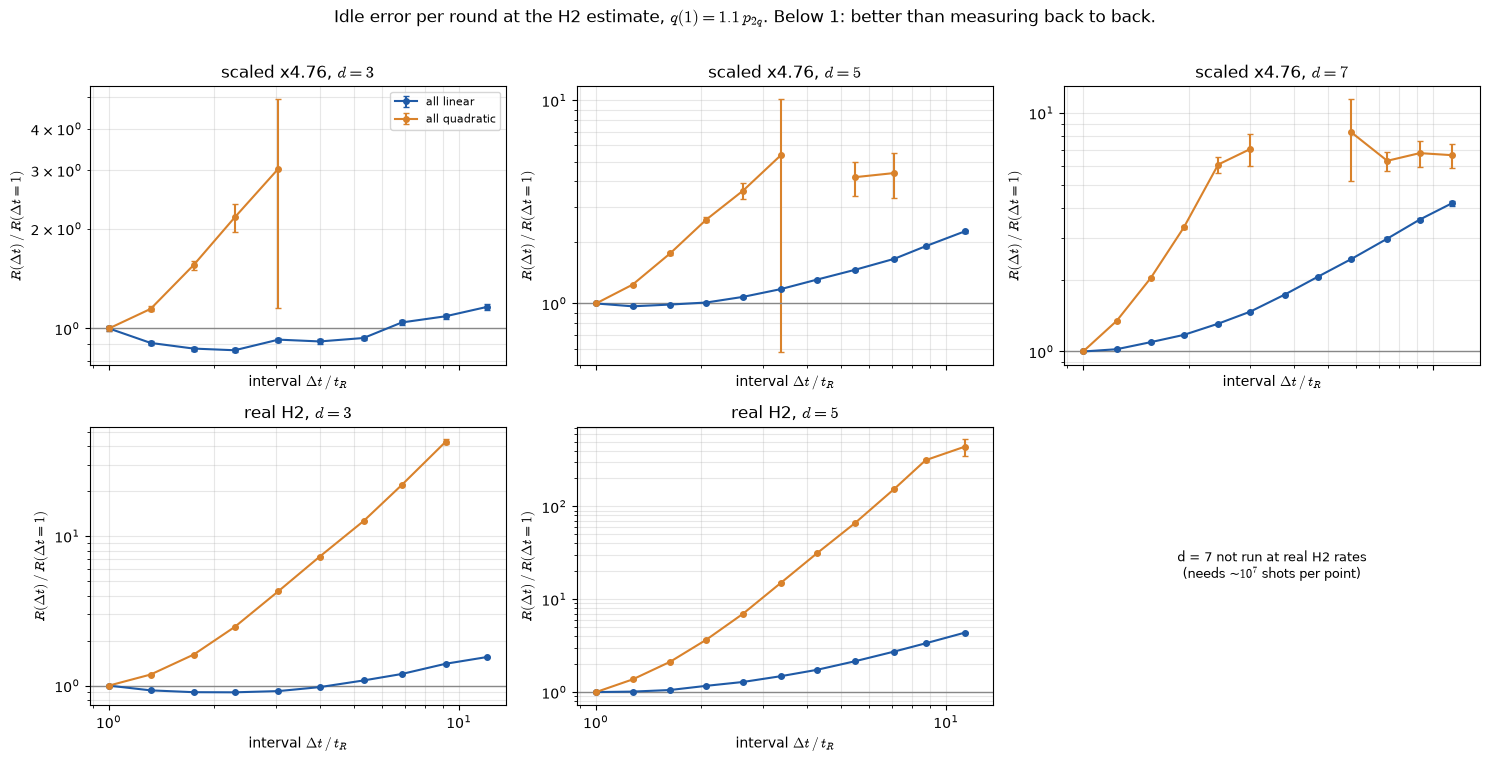

In [10]:
H2_GATES = dict(p1=H2['p1'], p2=H2['p2'], p_meas=0.5 * (H2['p_meas0'] + H2['p_meas1']),
                p_init=H2['p_init'])
Q1_REL = 1.1                                   # idle error per round, in units of p_2q (§7)


def h2_idle(fam, p2):
    q = Q1_REL * p2
    return (q, 0.0) if fam == 'lin' else (0.0, float(np.arcsin(np.sqrt(q)) ** 2))


CHECK = {'scaled x4.76': (GATES, (3, 5, 7), 100_000),
         'real H2': (H2_GATES, (3, 5), 500_000)}
t0 = time.time()
rows, H2CHK = [], {}
for scale, (gates, ds, shots) in CHECK.items():
    for d in ds:
        grid = [(dt, R) for dt, R in dt_grid(d) if dt <= 12]
        for fam in ('lin', 'quad'):
            g, c = h2_idle(fam, gates['p2'])
            pts = []
            for dt, R in grid:
                F = N = 0
                for sd in SEEDS:
                    f, n = run_point(d, dt, R, g, c, gates, 'X', shots, sd)
                    F, N = F + f, N + n
                r, sr = rate(F, N)
                pts.append((dt, r, sr))
            arr = np.array(pts)
            H2CHK[(scale, d, fam)] = arr
            # p_L near 1/2 gives no rate (NaN): those intervals are saturated, i.e. worst, not best
            n_sat = int(np.isnan(arr[:, 1]).sum())
            i = int(np.nanargmin(arr[:, 1]))
            gain = arr[0, 1] / arr[i, 1]
            z = (arr[0, 1] - arr[i, 1]) / np.hypot(arr[0, 2], arr[i, 2]) if i else 0.0
            th = FIT[d]['th']
            rows.append({'noise': scale, 'd': d, 'idle': 'all linear' if fam == 'lin' else 'all quadratic',
                         'lowest dt': round(arr[i, 0], 2),
                         'saturated points': n_sat,
                         'R(dt=1) / R(lowest)': round(gain, 3), 'difference / sigma': round(z, 1),
                         'formula dt*': round(dt_star_closed(g, c, np.exp(th[1]), th[2]), 2)
                                         if scale == 'scaled x4.76' else '-'})
    print(f'{scale} done [{time.time() - t0:.0f}s]')
H2T = pd.DataFrame(rows).set_index(['noise', 'd', 'idle'])
print('\n', H2T.to_string())

fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True)
for i, scale in enumerate(CHECK):
    for j, d in enumerate((3, 5, 7)):
        ax = axes[i, j]
        if (scale, d, 'lin') not in H2CHK:
            ax.axis('off'); ax.text(0.5, 0.5, f'd = {d} not run at real H2 rates\n(needs ~$10^7$ shots per point)',
                                    ha='center', va='center', transform=ax.transAxes, fontsize=9)
            continue
        for fam, col, lab in (('lin', BLUE, 'all linear'), ('quad', ORANGE, 'all quadratic')):
            a = H2CHK[(scale, d, fam)]
            y, e = a[:, 1] / a[0, 1], a[:, 1] / a[0, 1] * np.hypot(a[:, 2] / a[:, 1], a[0, 2] / a[0, 1])
            ax.errorbar(a[:, 0], y, yerr=e, marker='o', ms=4, capsize=2, color=col, label=lab)
        ax.axhline(1.0, color=GRAY, lw=1)
        ax.set_xscale('log'); ax.set_yscale('log'); ax.set_title(f'{scale}, $d = {d}$')
        ax.set_ylabel(r'$R(\Delta t)\,/\,R(\Delta t = 1)$'); ax.grid(alpha=.3, which='both')
        if i == 1 or (scale, d, 'lin') not in H2CHK:
            ax.set_xlabel(r'interval $\Delta t\,/\,t_R$')
axes[0, 0].legend(fontsize=8)
for ax in axes[0]:
    ax.set_xlabel(r'interval $\Delta t\,/\,t_R$')
fig.suptitle(r'Idle error per round at the H2 estimate, $q(1) = 1.1\,p_{2q}$. Below 1: better than measuring back to back.', y=1.01)
fig.tight_layout()
fig.savefig(FIGDIR / '07e_h2_ratio_direct.png', dpi=130, bbox_inches='tight', facecolor='white')
plt.show()

**Result of §7b.**

| noise | d | all linear: best Δt | gain over Δt = 1 | all quadratic: best Δt |
| --- | --- | --- | --- | --- |
| scaled ×4.76 | 3 | 2.29 | 16% (10σ) | 1 |
| scaled ×4.76 | 5 | 1.27 | 3% (3.5σ) | 1 |
| scaled ×4.76 | 7 | 1 | — | 1 |
| real H2 | 3 | 2.29 | 11% (17σ) | 1 |
| real H2 | 5 | 1 | — | 1 |

- **Quadratic dephasing: back to back is best in every case.** Waiting only makes it worse, fast
  (the rate at Δt = 3 is 2–5× higher). This agrees with the formula (Δt\* = 0.57–0.79).
- **Linear dephasing: a short wait helps only at d = 3**, and only a little (11–16%). At d = 5 the
  gain is 3% (scaled) or nothing (real rates); at d = 7, nothing. The formula's extrapolation
  (2.54, 1.43, 0.94 at d = 3, 5, 7, scaled) matches what is simulated (2.29, 1.27, 1).
- **So §7's extrapolated H2 conclusion holds when checked directly:** at H2's estimated idle-to-gate
  ratio, there is little or nothing to gain from waiting between rounds, and nothing at d ≥ 5 with
  H2's real gate rates.
- Still assumed, not measured: the H2 ratio itself (q(1) ≈ 1.1·p_2q, from 6 layers per round, §7).

Saturated points (p_L ≈ ½ at long Δt under quadratic dephasing) carry no rate and are skipped.

## 8. Figures

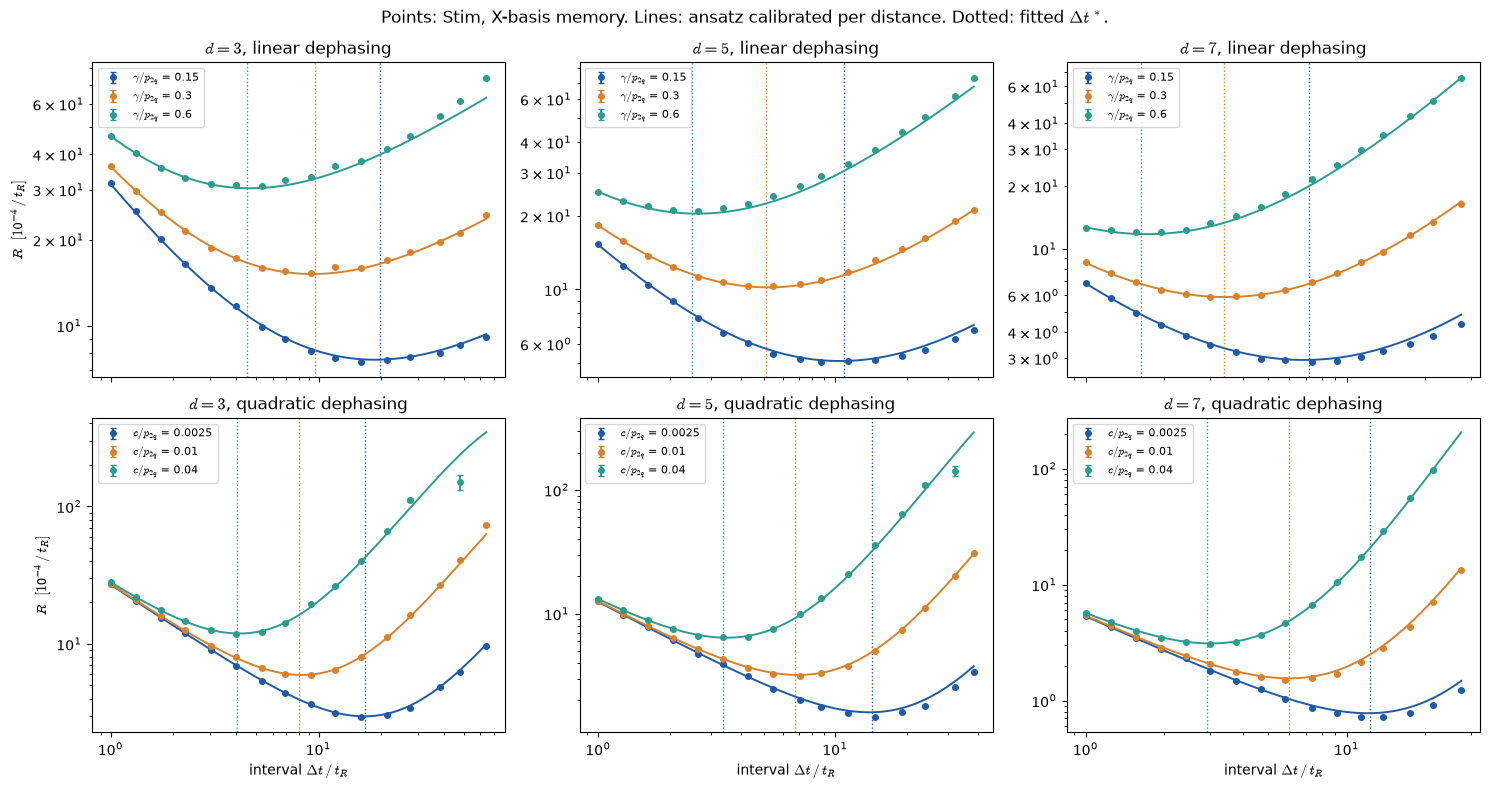

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8), sharex='col')
dense = lambda d: np.geomspace(1, T / d, 300)
for j, d in enumerate(DISTANCES):
    th = FIT[d]['th']
    for i, (fam, vals) in enumerate((('lin', LIN), ('quad', QUAD))):
        ax = axes[i, j]
        for v, col in zip(vals, (BLUE, ORANGE, AQUA)):
            df = CURVES[(fam, v, d)]
            ax.errorbar(df.dt, df.r * 1e4, yerr=df.sr * 1e4, fmt='o', ms=4, color=col, capsize=2,
                        label=(r'$\gamma/p_{2q}$' if fam == 'lin' else r'$c/p_{2q}$') + f' = {v}')
            ax.plot(dense(d), model(dense(d), *idle_of((fam, v, d)), *th) * 1e4, color=col, lw=1.4)
            ax.axvline(OPT[(fam, v, d)]['dt_star'], color=col, ls=':', lw=1)
        ax.set_xscale('log'); ax.set_yscale('log')
        ax.set_title(f"$d = {d}$, {'linear' if fam == 'lin' else 'quadratic'} dephasing")
        if j == 0:
            ax.set_ylabel(r'$R$  $[10^{-4}\,/\,t_R]$')
        if i == 1:
            ax.set_xlabel(r'interval $\Delta t\,/\,t_R$')
        ax.legend(fontsize=8)
fig.suptitle(r'Points: Stim, X-basis memory. Lines: ansatz calibrated per distance. Dotted: fitted $\Delta t^*$.')
fig.tight_layout()
fig.savefig(FIGDIR / '07a_rate_vs_dt.png', dpi=130, bbox_inches='tight', facecolor='white')

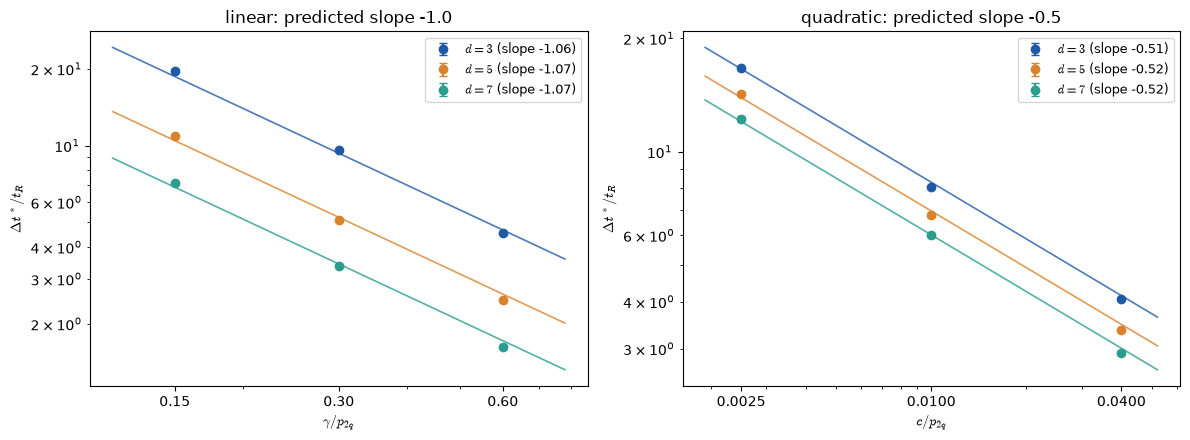

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, (fam, vals, expect) in zip(axes, (('lin', LIN, -1.0), ('quad', QUAD, -0.5))):
    for d in DISTANCES:
        o = [OPT[(fam, v, d)] for v in vals]
        y = np.array([x['dt_star'] for x in o])
        err = np.array([[x['dt_star'] - x['lo'] for x in o], [x['hi'] - x['dt_star'] for x in o]])
        ax.errorbar(vals, y, yerr=np.abs(err), marker='o', ms=6, capsize=3, color=DCOL[d], lw=0,
                    elinewidth=1.5, label=f'$d = {d}$ (slope {loglog_slope(fam, d)[0]:.2f})')
        th = FIT[d]['th']
        xs = np.geomspace(min(vals) / 1.3, max(vals) * 1.3, 50)
        g = [dt_star_closed(*idle_of((fam, v, d)), np.exp(th[1]), th[2]) for v in xs]
        ax.plot(xs, g, color=DCOL[d], lw=1.2, alpha=.8)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel(r'$\gamma/p_{2q}$' if fam == 'lin' else r'$c/p_{2q}$')
    ax.set_xticks(vals); ax.xaxis.set_major_formatter(plt.ScalarFormatter())
    ax.xaxis.set_minor_formatter(plt.NullFormatter())
    ax.set_ylabel(r'$\Delta t^*/t_R$')
    ax.set_title(f"{'linear' if fam == 'lin' else 'quadratic'}: predicted slope {expect}")
    ax.legend(fontsize=9)
fig.tight_layout()
fig.savefig(FIGDIR / '07b_dt_star_scaling.png', dpi=130, bbox_inches='tight', facecolor='white')

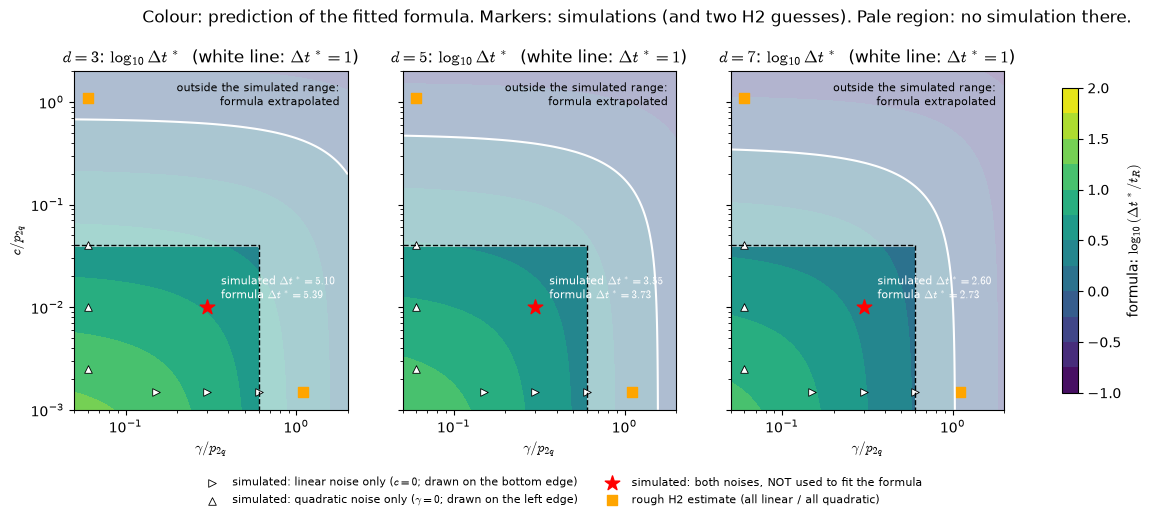

In [13]:
G, C = np.meshgrid(np.geomspace(0.05, 2, 120), np.geomspace(1e-3, 2, 120))
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, d in zip(axes, DISTANCES):
    th = FIT[d]['th']
    Z = np.vectorize(lambda g, c: dt_star_closed(g * P2, c * P2, np.exp(th[1]), th[2]))(G, C)
    cs = ax.contourf(G, C, np.log10(np.maximum(Z, 0.1)), levels=np.linspace(-1, 2, 13), cmap='viridis')
    ax.contour(G, C, Z, levels=[1.0], colors='white', linewidths=1.5)
    # grey out what no simulation constrains: beyond the largest simulated gamma or c
    outside = (G > max(LIN)) | (C > max(QUAD))
    ax.contourf(G, C, outside.astype(float), levels=[0.5, 1.5], colors='white', alpha=0.6)
    ax.plot([G.min(), max(LIN), max(LIN)], [max(QUAD), max(QUAD), C.min()], color='k', ls='--', lw=1)
    ax.text(0.97, 0.97, 'outside the simulated range:\nformula extrapolated', transform=ax.transAxes,
            ha='right', va='top', fontsize=8, color='k')
    ax.scatter([l for l in LIN], [1.5e-3] * 3, marker='>', color='w', s=30, edgecolors='k', linewidths=0.6, label=r'simulated: linear noise only ($c = 0$; drawn on the bottom edge)')
    ax.scatter([0.06] * 3, QUAD, marker='^', color='w', s=30, edgecolors='k', linewidths=0.6, label=r'simulated: quadratic noise only ($\gamma = 0$; drawn on the left edge)')
    ax.scatter(*MIXED, marker='*', color='r', s=120, label='simulated: both noises, NOT used to fit the formula')
    g_m, c_m = idle_of(('mixed', MIXED))
    sim = OPT[('mixed', MIXED, d)]['dt_star']
    pred = dt_star_closed(g_m, c_m, np.exp(th[1]), th[2])
    ax.annotate(f'simulated $\\Delta t^* = {sim:.2f}$\nformula $\\Delta t^* = {pred:.2f}$', MIXED, xytext=(10, 6),
                textcoords='offset points', color='w', fontsize=8)
    ax.scatter([1.1, 0.06], [1.5e-3, 1.1], marker='s', color='orange', s=60, label='rough H2 estimate (all linear / all quadratic)')
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel(r'$\gamma/p_{2q}$'); ax.set_title(f'$d = {d}$: $\\log_{{10}}\\Delta t^*$  (white line: $\\Delta t^* = 1$)')
axes[0].set_ylabel(r'$c/p_{2q}$'); fig.legend(*axes[0].get_legend_handles_labels(), loc='upper center', ncol=2, fontsize=8,
           bbox_to_anchor=(0.45, -0.02), frameon=False)
fig.suptitle('Colour: prediction of the fitted formula. Markers: simulations (and two H2 guesses). Pale region: no simulation there.', y=1.02)
fig.colorbar(cs, ax=axes, shrink=.9, label=r'formula: $\log_{10}(\Delta t^*/t_R)$')
fig.savefig(FIGDIR / '07c_dt_star_map.png', dpi=130, bbox_inches='tight', facecolor='white')

### The same prediction as a line plot

Δt\* against the **idle error per round**, q(1)/p_2q: the Z error a data qubit picks up over one
round-duration t_R. Two limits bracket any device: all of it linear (q(1) = γ) or all of it
quadratic (q(1) = sin²√c ≈ c). Points: simulations, with their 16–84% intervals. Lines: the fitted
formula, solid where simulations exist and dotted where it is extrapolated. Below the grey line
(Δt\* = 1) it does not pay to wait between rounds. The orange band is the rough H2 estimate
(q(1) ≈ 1.1·p_2q, assuming 6 depth-1 layers per round; §7).

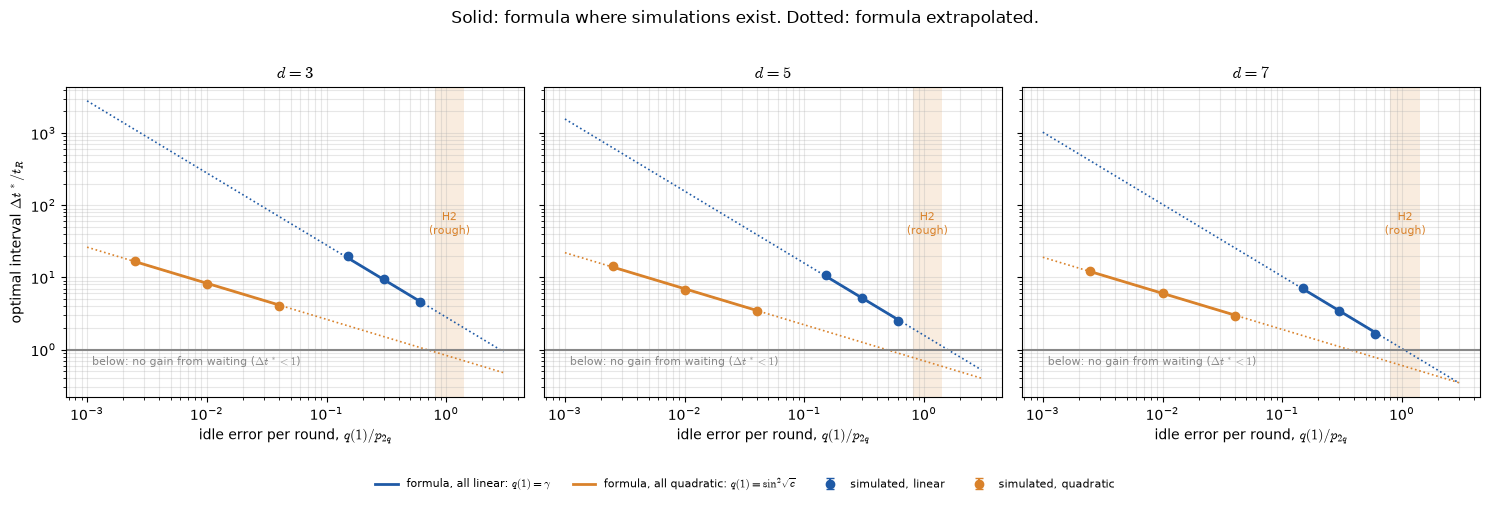

In [14]:
x = np.geomspace(1e-3, 3, 300)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), sharey=True)
for ax, d in zip(axes, DISTANCES):
    th = FIT[d]['th']
    pe, al = np.exp(th[1]), th[2]
    for fam, vals, col, lab in (('lin', LIN, BLUE, r'all linear: $q(1) = \gamma$'),
                                ('quad', QUAD, ORANGE, r'all quadratic: $q(1) = \sin^2\!\sqrt{c}$')):
        if fam == 'lin':
            pred = np.array([dt_star_closed(xi * P2, 0.0, pe, al) for xi in x])
            xs = np.array(vals)
        else:
            cs_ = np.arcsin(np.sqrt(x * P2)) ** 2          # c giving q(1) = x * p_2q
            pred = np.array([dt_star_closed(0.0, ci, pe, al) for ci in cs_])
            xs = np.sin(np.sqrt(np.array(vals) * P2)) ** 2 / P2
        inside = (x >= xs.min()) & (x <= xs.max())
        ax.plot(x[inside], pred[inside], color=col, lw=2, label=f'formula, {lab}')
        ax.plot(x, pred, color=col, lw=1.2, ls=':')
        o = [OPT[(fam, v, d)] for v in vals]
        y = np.array([q['dt_star'] for q in o])
        err = np.abs(np.array([[q['dt_star'] - q['lo'] for q in o], [q['hi'] - q['dt_star'] for q in o]]))
        ax.errorbar(xs, y, yerr=err, fmt='o', ms=6, color=col, capsize=3, label='simulated, ' + ('linear' if fam == 'lin' else 'quadratic'))
    ax.axhline(1.0, color=GRAY, lw=1.5)
    ax.text(x[0] * 1.1, 0.8, r'below: no gain from waiting ($\Delta t^* < 1$)', fontsize=8, color=GRAY, va='top')
    ax.axvspan(0.8, 1.4, color=ORANGE, alpha=0.15, lw=0)
    ax.text(1.06, ax.get_ylim()[1] if False else 40, 'H2\n(rough)', ha='center', fontsize=8, color=ORANGE)
    ax.set_xscale('log'); ax.set_yscale('log')
    ax.set_xlabel(r'idle error per round, $q(1)/p_{2q}$')
    ax.set_title(f'$d = {d}$')
    ax.grid(alpha=.3, which='both')
axes[0].set_ylabel(r'optimal interval $\Delta t^*/t_R$')
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, loc='upper center', ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.02), frameon=False)
fig.suptitle('Solid: formula where simulations exist. Dotted: formula extrapolated.', y=1.02)
fig.tight_layout()
fig.savefig(FIGDIR / '07d_dt_star_vs_idle_error.png', dpi=130, bbox_inches='tight', facecolor='white')
plt.show()

## 9. Findings

**1. A Z-basis memory is blind to this idle noise; an X-basis memory is not.** At d = 3, turning
the mixed idle noise on changes the Z-basis `p_L` by at most 2.1σ over 16 intervals (chance
level), and the X-basis `p_L` by up to 304σ. With idle noise off, neither basis has an interior
optimum: the rate falls all the way to the longest interval. The Z-basis memory used in 03–06c
could not have seen dephasing at all.

**2. Every curve has an interior optimum**: all 21 (7 idle settings × d = 3, 5, 7), and both
held-out sweeps.

**3. The form of the idle noise sets how Δt* scales with its size, as derived.** Quadratic
dephasing: `log Δt*` against `log c` has slope −0.510, −0.521, −0.517 at d = 3, 5, 7, within
0.9–2.0σ of the predicted −1/2. Linear dephasing: slope −1.06 at every distance against the
predicted −1, so 2.9–3.3σ steeper. That is a 6% excess the ansatz does not capture.

**4. Under quadratic dephasing, distance barely moves the optimum.** From d = 3 to 7, Δt*
shortens 2.85× under linear dephasing (γ = 0.3·p_2q: 9.64 → 3.38) but only 1.34× under quadratic
(c = 0.01·p_2q: 8.05 → 6.01). The calibrated closed form gives 2.72× and 1.38×. The difference
is the square root in the quadratic limit, together with an α that grows slowly with d
(finding 5).

**5. α grows with distance more slowly than the paper's.** The fitted α is 1.48, 1.81 and 2.18 at
d = 3, 5 and 7, an implied g of 0.74, 0.60 and 0.54, against the paper's g = 0.8 (fitted at
d = 11–27). α rises about 0.35 per step of 2 in d, against the paper's 0.8. `p_e` (effective
extraction error) is 1.35, 1.27 and 1.21 × p_2q.

**6. The closed form predicts Δt* to within about 5%, but not within the statistical error.**
In-sample, all 18 pure curves land within −5.3% to +5.5% of the measured Δt*. Out-of-sample,
the mixed point is predicted 5.0–5.7% too long at all three distances (5.39 vs 5.10, 3.73 vs
3.55, 2.73 vs 2.60). The bootstrap intervals are ±1–2%, so these deviations are statistically
significant: the formula is good to about 5%, not exact. The closed form and the numerical
minimum of the calibrated ansatz agree to 0.02, so the small-angle step costs nothing here.

**7. Δt* is not invariant under scaling all the noise down, and the direction matters.** Halving
every rate at d = 5 shortens Δt* by 14% under linear dephasing (5.12 → 4.41) and 4% under
quadratic (6.77 → 6.51). Prediction 3 fails. Both shifts are explained by one change: holding
`p_e/p_2q` fixed, the linear shift implies α = 1.94 and the quadratic shift α = 1.91, against 1.81
at full noise. Lower noise is further below threshold, so the effective exponent grows. α
therefore depends on the noise level, not only on d. Since the simulation runs 4.8× above H2's
gate error, **every Δt* here is biased long relative to H2.**

**8. H2-like numbers put the optimum at or below one round.** Under this notebook's
assumptions (6 depth-1 layers per round, so idle error per round ≈ 1.1·p_2q), the closed form gives
Δt* of 2.5 (all linear) to 0.8 (all quadratic) at d = 3, and 1.4 to 0.7 at d = 5, in units of
one extraction round, and finding 7 says these are overestimates. On those assumptions there is
little or no benefit in inserting idle time on H2: rounds should run back to back. The trade-off
exists, but H2's idle error per round is already comparable to its gate error, which puts it
in the corner of the map where waiting does not pay.

### Limits

- **The ansatz does not fit whole curves**: χ²/dof is 7–15, driven by the long-interval
  tails (07a). It holds near the minimum, which is all the Δt* prediction uses.
- **The intervals are statistical only.** The same two seeds are used at every Δt, so points
  along a curve are correlated, and the parabola estimator's own bias is not included. Read
  agreement at the ~5% level, not the ±1% the intervals suggest.
- **Noise scaled ×4.76** for measurability. Finding 7 shows this biases Δt* long.
- **Not modelled**:
  - dephasing on the ancillas during extraction (independent of Δt; it shifts `p_e`);
  - spontaneous emission, leakage, crosstalk, and the asymmetric readout (a symmetric mean is
    used);
  - spatially correlated dephasing (a global field drift hits all qubits at once);
  - coherent accumulation across qubits (quadratic dephasing is Pauli-twirled and assumed to
    reset at each round);
  - **dynamical decoupling**, which H2 uses and which suppresses exactly the quadratic term.
- **The H2 placement rests on two assumptions**: 6 layers per round, and an unknown split
  between the linear and quadratic terms. It is a direction, not a number.
- **Stim's generated circuit**: no native-gate decomposition, and the idle channel is applied
  once before each round rather than spread through it. Rotated code only, T = 192.

### Next

1. Calibrate α at H2's actual noise level (or extrapolate α(p) from two or three noise scales)
   before quoting any H2 Δt*.
2. Pin down the linear/quadratic split and the round duration from the
   [hardware specifications repository](https://github.com/CQCL/quantinuum-hardware-specifications).
3. Add ancilla dephasing during extraction, and test dynamical decoupling as a reduction of `c`.